In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data exported from Week 5.
regression_df = pd.read_csv(
    "regression_data.csv",
    parse_dates=["hour_local"]
)

# All remaining columns are predictors.
core_features = regression_df.columns.drop(
    ["hour_local", "avg_departure_delay"]
).tolist()

print(f"Loaded {len(regression_df):,} rows and {len(core_features)} predictors.")

Loaded 28,499 rows and 23 predictors.


In [2]:
# Sort our data by date and time
data = regression_df.sort_values("hour_local")

# X contains the features we use to make predictions
X = data[core_features]

# y contains the variable we want to predict
y = data["avg_departure_delay"]

In [3]:
# Sort data chronologically
data = regression_df.sort_values("hour_local")

X = data[core_features]
y = data["avg_departure_delay"]

In [4]:
# Define split points
train_end = int(len(X) * 0.70)
val_end = int(len(X) * 0.85)

# Training data
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation data
X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

# Testing data
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Training rows (70%):", len(X_train))
print("Validation rows (15%):", len(X_val))
print("Testing rows (15%):", len(X_test))

Training rows (70%): 19949
Validation rows (15%): 4275
Testing rows (15%): 4275


In [5]:
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import RFE
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [11]:
#Scaling data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)

In [13]:
# Create model
ridge_model = Ridge(alpha=1.0)

#Trying recursive feature elimination for different amounts of features
for i in range (3, 24):
  rfe = RFE(estimator=ridge_model, n_features_to_select=i, step=1)
  rfe.fit(X_train_scaled, y_train)

  #Using the validation data to make predictions
  predictions = rfe.predict(X_val_scaled)

  #Seeing how well the model created by rfe performs on the validation data
  r2 = r2_score(y_val, predictions)
  rmse = root_mean_squared_error(y_val, predictions)
  mae = mean_absolute_error(y_val, predictions)

  #Printing the results for our reference
  print(f"{i}{" features: r2 is "} {r2}")

3 features: r2 is  -0.004360829202461058
4 features: r2 is  0.01016928429133579
5 features: r2 is  0.06347121058662308
6 features: r2 is  0.055109054386548006
7 features: r2 is  0.0629265148634055
8 features: r2 is  0.06214272298515522
9 features: r2 is  0.062275462534287396
10 features: r2 is  0.060431774156358586
11 features: r2 is  0.06592819647160808
12 features: r2 is  0.06453426127898432
13 features: r2 is  0.06810326909440001
14 features: r2 is  0.07313798255739212
15 features: r2 is  0.07420436189779445
16 features: r2 is  0.07365801933825566
17 features: r2 is  0.07444846069061428
18 features: r2 is  0.07405597718975843
19 features: r2 is  0.07364727511882518
20 features: r2 is  0.07342815035750339
21 features: r2 is  0.07377107378872261
22 features: r2 is  0.07383419585723217
23 features: r2 is  0.07386878949820586


In [16]:
#Find the features that RFE selected:
rfe = RFE(estimator=ridge_model, n_features_to_select=17, step=1)
rfe.fit(X_train_scaled, y_train)

selected_features = X_train.columns[rfe.support_]
print(selected_features)

Index(['origins', 'avg_distance', 'avg_scheduled_flight_time', 'wind_max_ms',
       'visibility_min_m', 'dew_point_spread_c', 'freezing_deficit_c',
       'high_wind', 'traffic_low_visibility', 'hour_sin', 'hour_cos',
       'season_sin', 'season_cos', 'dow_tue', 'dow_wed', 'dow_fri', 'dow_sun'],
      dtype='object')


In [17]:
#Make new model
rfe_ridge=Ridge(alpha=1.0)

#Get columns that are included
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]
X_val_selected = X_val[selected_features]

#Re-scale data
X_train_selected_scaled = scaler.fit_transform(X_train_selected)
X_test_selected_scaled = scaler.transform(X_test_selected)
X_val_selected_scaled = scaler.transform(X_val_selected)

rfe_ridge.fit(X_train_selected_scaled, y_train)

#Test
ridge_predictions = rfe_ridge.predict(X_test_selected_scaled)
r2 = r2_score(y_test, ridge_predictions)
rmse = root_mean_squared_error(y_test, ridge_predictions)
mae = mean_absolute_error(y_test, ridge_predictions)
print(f"{"r2: "} {r2}")
print(f"{"RMSE: "} {rmse}")
print(f"{"MAE"} {mae}")

r2:  0.07673655135046209
RMSE:  40.91569773060124
MAE 15.866242624410784


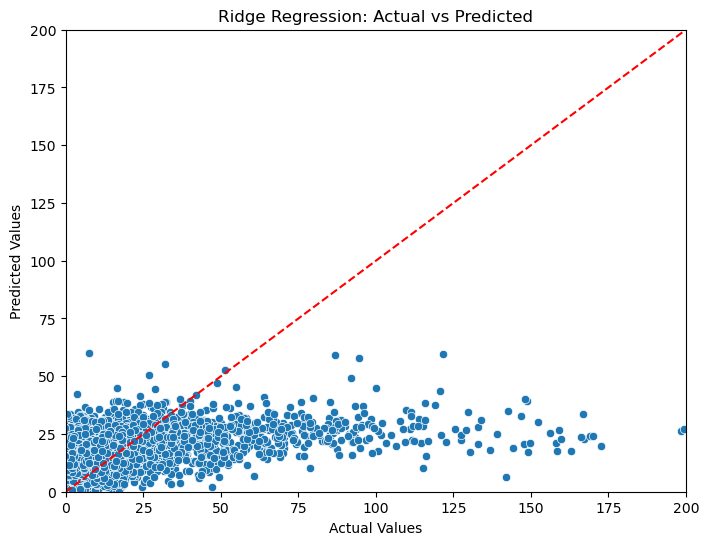

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=ridge_predictions)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Ridge Regression: Actual vs Predicted")
plt.xlim(0, 200)
plt.ylim(0, 200)
plt.show()

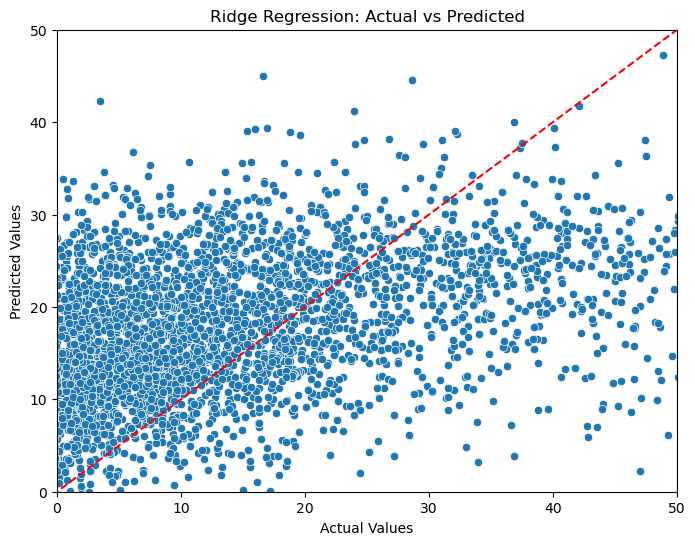

In [25]:
# Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=ridge_predictions)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Ridge Regression: Actual vs Predicted")
plt.xlim(0, 50)
plt.ylim(0, 50)
plt.show()

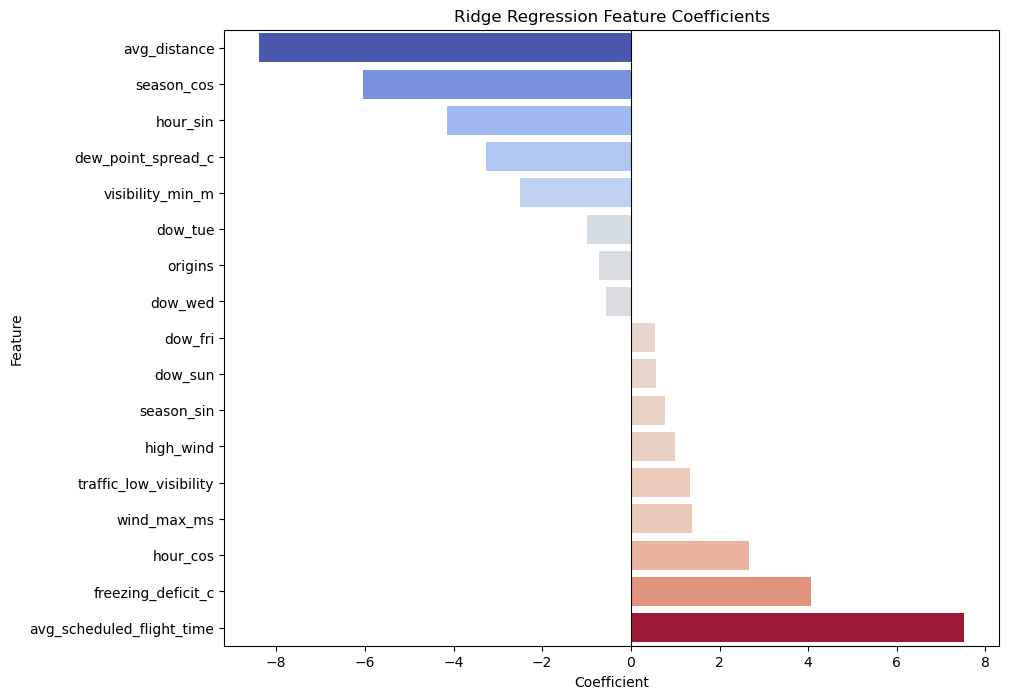

In [21]:
coefficients = rfe_ridge.coef_

# Create dataframe
coef_df = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Coefficient': coefficients
})

# Sort coefficients
coef_df = coef_df.sort_values('Coefficient')

# Plot
plt.figure(figsize=(10, 8))
sns.barplot(
    data=coef_df,
    x='Coefficient',
    y='Feature',
    hue='Coefficient',
    palette='coolwarm',
    legend=False
)

plt.title("Ridge Regression Feature Coefficients")
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

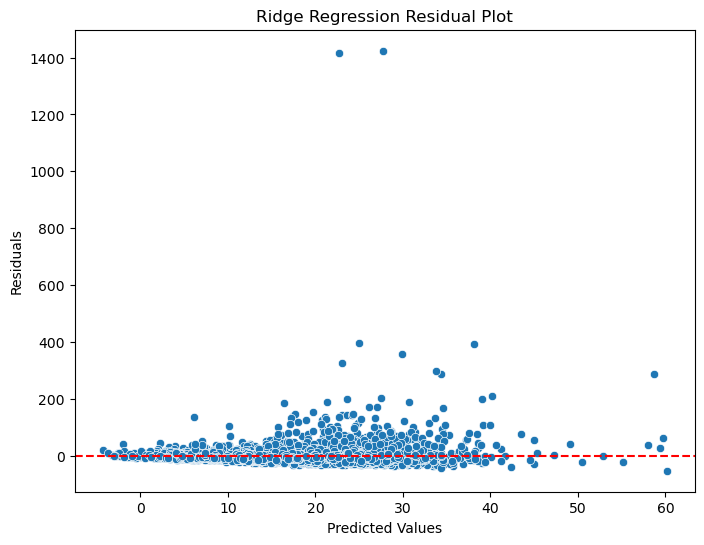

In [29]:
residuals = y_test - ridge_predictions

plt.figure(figsize=(8, 6))
sns.scatterplot(x=ridge_predictions, y=residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Ridge Regression Residual Plot")
plt.show()

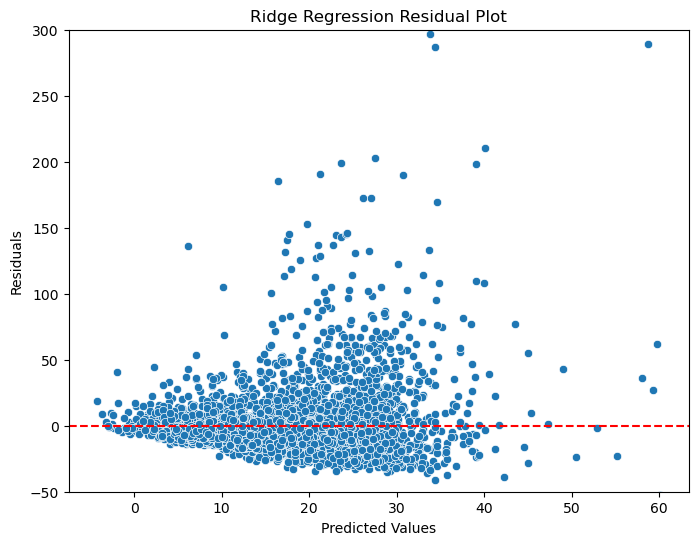

In [30]:
residuals = y_test - ridge_predictions

plt.figure(figsize=(8, 6))
sns.scatterplot(x=ridge_predictions, y=residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Ridge Regression Residual Plot")
plt.ylim(-50, 300)
plt.show()

**Explanation:**

I first imported the dataframe and sorted all the rows in chronological order. I then split the data into training, validation, and testing sections, with a 70-15-15 split, and I scaled the data. Ridge regression does much better when data is scaled because data with larger ranges can disproportionately affect the model in a way that worsens performance, but scaling the data keeps all columns in a smaller range.

I then started to find the best possible ridge model using recursive feature elimination (RFE). RFE takes a number of features you want the model to include and recursively eliminates the worst-performing feature until the model only uses the given amount of features. For example, our dataframe originally has 23 features. If I give RFE 12 features, then it will start by creating a ridge model of all 23 features, and then determine which feature is contributing to the model the least. It will then drop that feature, and do the same process with the remaining 22 features, until it reaches a model that has only 12 features. To implement this, I looped through RFE with a range of potential numbers of features (3 to 23) and had the r2 scores printed so that I could see which model performed the best. The loop trained the model on the training data set, and tested on the validation data set, since validation data is used to compare models before final testing in order to avoid data leakage. Running this script showed that the best-performing ridge model used 17 of the 23 features, which I then found: origins, avg_distance, avg_scheduled_flight_time, wind_max_ms, visibility_min_m, dew_point_spread_c, freezing_deficit_c, high_wind, traffic_low_visibility, hour_sin, hour_cos, season_sin, season_cos, dow_tue, dow_wed, dow_fri, dow_sun.

I then created this best-performing model, rfe_ridge, using only those 17 selected columns. This new model was then able to be tested with the testing data set to get the final performance metrics:

- r2: 0.07674
- RMSE: 40.9157
- MAE: 15.8662

Overall, the metrics are not the best, and show that ridge may not be the best predictor in general for our dataframe. However, this model is still the best-performing ridge model compared to models with other numbers and combinations of features.

To visualize this model, I first created a scatter plot that shows the ridge model's predictions as a line and the actual data from the testing data as points. As can be seen, the ridge model does pass through a large cluster of the data, but after a certain point it stops predicting accurately at all. The second plot is a more zoomed-in version of the cluster the model passes through, and it can be seen that the model mostly does align with the direction of the data, visually skewing more to the left of the data's direction because there is a higher concentration of data on the left.

The third plot is a bar plot that shows and compares the values of the coefficients of the ridge model. As can be seen, the values that contribute the most to the model's predictions are the average flight distance and average scheduled flight time, and the values that contribute the least are those that relate to the day of the week.

The fourth and fifth plots are also scatterplots that show the residuals for predicted values as points with a line marking where y=0, meaning points where the predictions were accurate. The fifth plot is a more zoomed-in version of the fourth plot, which allows us to see the general shape of the residuals better, especially since the fourth model is affected